# Phase 3: PlantVillage and PlantDoc preliminary image audit

This notebook accompanies `scripts/analyze_data.py`. It reports measured image counts, class imbalance, dimensions, unreadable files, exact duplicates, related-leaf indicators, and case-insensitive path collisions. The original dataset category names are retained; category matching is a separate task.

## 1. Run the inventory

Run this once after `python scripts/prepare_data.py`; rerun if the underlying files change. Set `DATA_ROOT` if using another machine. The script records source versions from the local manifest and scans *all supported image files* to count categories, decode image dimensions and modes, flag unreadable files, and identify exact duplicates and related-leaf groups.


In [118]:
from pathlib import Path
import json
import subprocess
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts" / "analyze_data.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent  # notebook opened from scripts/
DATA_ROOT = Path.home() / "datasets" / "cecs551-plant-disease"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "eda"
subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "analyze_data.py"),
                "--data-root", str(DATA_ROOT), "--output-dir", str(OUTPUT_DIR)], check=True)


Inspected 10,000/56,883 images
Inspected 20,000/56,883 images
Inspected 30,000/56,883 images
Inspected 40,000/56,883 images
Inspected 50,000/56,883 images
{
  "analyzed_utc": "2026-11-12T14:05:18.802787+00:00",
  "data_root": "/Users/max/datasets/cecs551-plant-disease",
  "plantvillage_revision": "9e97599868962bd0079b8db4b7f1efa9185fa1e7",
  "plantdoc_revision": "5467f6012d78d1c446145d5f582da6096f852ae8",
  "images_by_dataset": {
    "plantdoc": 2578,
    "plantvillage": 54305
  },
  "unreadable_images": 0,
  "unassigned_source_images": 0,
  "missing_source_images": 0,
  "resolved_plantvillage_leaf_ids": 41111,
  "exact_duplicate_hash_groups": 33,
  "exact_duplicate_cross_partition_groups": 16,
  "exact_duplicate_groups_by_experiment_impact": {
    "training_test_overlap": 5,
    "duplicate_test": 2,
    "duplicate_training": 14,
    "no_direct_impact": 12
  },
  "exact_duplicate_label_conflict_groups": 9,
  "exact_duplicate_cross_dataset_groups": 0,
  "exact_duplicate_cross_source_spl

CompletedProcess(args=['/Users/max/.venvs/cecs551-plant-disease/bin/python', '/Users/max/Documents/CSULB/CECS551/CECS-551-Plant-Disease-Classification/scripts/analyze_data.py', '--data-root', '/Users/max/datasets/cecs551-plant-disease', '--output-dir', '/Users/max/Documents/CSULB/CECS551/CECS-551-Plant-Disease-Classification/outputs/eda'], returncode=0)

In [119]:
import pandas as pd
import matplotlib.pyplot as plt

inventory = pd.read_csv(OUTPUT_DIR / "image_inventory.csv", keep_default_na=False)
counts = pd.read_csv(OUTPUT_DIR / "class_counts.csv", keep_default_na=False)
flags = pd.read_csv(OUTPUT_DIR / "quality_flags.csv", keep_default_na=False)
summary = json.loads((OUTPUT_DIR / "summary.json").read_text())
print("PlantVillage revision:", summary["plantvillage_revision"])
print("PlantDoc revision:", summary["plantdoc_revision"])
print("Images counted:", summary["images_by_dataset"])
print("Case-insensitive filename collision groups:", summary["case_insensitive_filename_collision_groups"])
DATASET_LABELS = {"plantvillage": "PlantVillage", "plantdoc": "PlantDoc"}
display(counts)


PlantVillage revision: 9e97599868962bd0079b8db4b7f1efa9185fa1e7
PlantDoc revision: 5467f6012d78d1c446145d5f582da6096f852ae8
Images counted: {'plantdoc': 2578, 'plantvillage': 54305}
Case-insensitive filename collision groups: 6


,dataset,category,split,file_count,readable_count,unreadable_count
0,plantdoc,Apple Scab Leaf,test,10,10,0
1,plantdoc,Apple Scab Leaf,train,83,83,0
2,plantdoc,Apple leaf,test,9,9,0
3,plantdoc,Apple leaf,train,82,82,0
4,plantdoc,Apple rust leaf,test,10,10,0
...,...,...,...,...,...,...
126,plantvillage,Tomato___Tomato_Yellow_Leaf_Curl_Virus,train,4257,4257,0
127,plantvillage,Tomato___Tomato_mosaic_virus,test,66,66,0
128,plantvillage,Tomato___Tomato_mosaic_virus,train,307,307,0
129,plantvillage,Tomato___healthy,test,330,330,0


## 2. Class balance by original category

Each bar is the measured total for one category, with its original train/test membership shown separately. These are **file counts**, including any unreadable files; the table above also records readable counts.


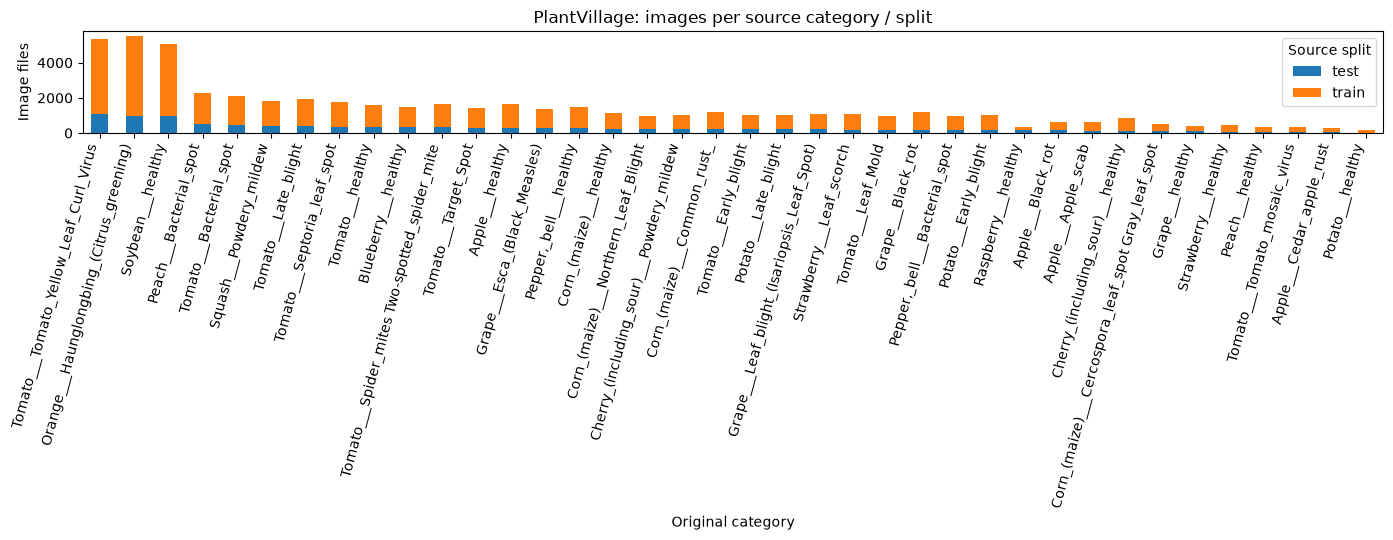

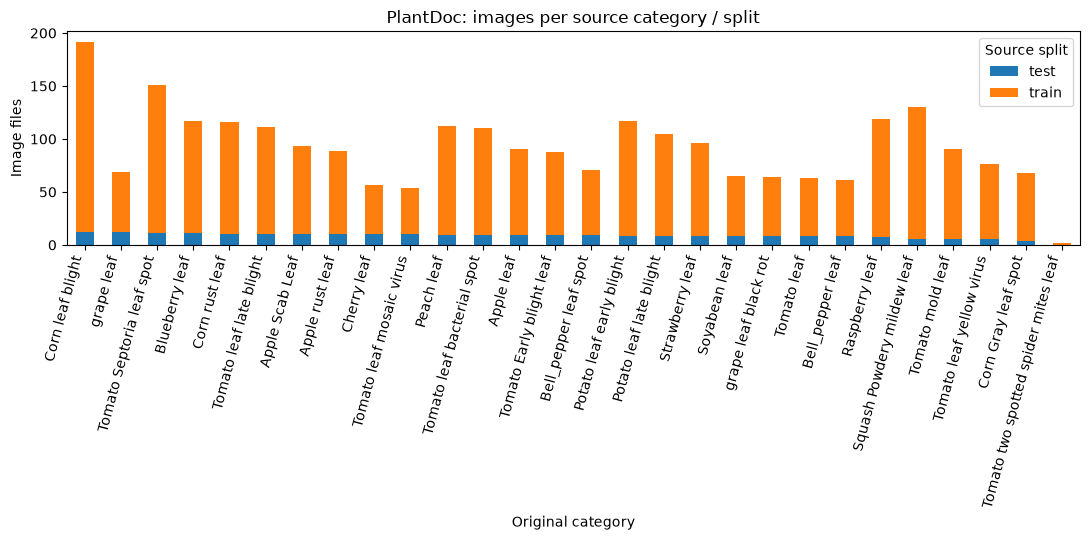

In [120]:
for dataset, display_name in DATASET_LABELS.items():
    subset = counts[counts["dataset"] == dataset]
    pivot = subset.pivot_table(index="category", columns="split", values="file_count",
                               aggfunc="sum", fill_value=0)
    ax = pivot.sort_values(by=list(pivot.columns), ascending=False).plot(
        kind="bar", stacked=True, figsize=(max(11, len(pivot) * .37), 5.5))
    ax.set(title=f"{display_name}: images per source category / split", ylabel="Image files", xlabel="Original category")
    ax.legend(title="Source split")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{dataset.lower()}_class_balance.png", dpi=160)
    plt.show()


## 3. Image dimensions

The dataset-wide table below shows minimum, median, and maximum image width/height and non-square counts, combining each dataset's original train/test splits. These statistics use only successfully decoded images. Split-specific statistics and unreadable-file counts are available in `image_statistics.json`.

For each dataset, show the 20 most frequent original resolutions, with image counts and percentages of readable images. The complete frequency tables remain available as `dimension_frequencies["plantvillage"]` and `dimension_frequencies["plantdoc"]` in this notebook. PlantVillage source splits and PlantDoc train/test folders are combined within each dataset. Bubble charts plot width against height; marker area increases with the number of images at each resolution (with a minimum size so rare resolutions remain visible). The dashed diagonal represents square images.

Different sizes may require resizing, but a crop policy must avoid losing useful leaf details.


In [121]:
image_statistics = pd.DataFrame(
    json.loads((OUTPUT_DIR / "image_statistics.json").read_text())["partitions"]
)
overall_statistics = image_statistics[image_statistics["split"].eq("all")]

def dimension_range(row, dimension):
    return " / ".join(
        f"{row[f'{dimension}_{stat}']:g}" if pd.notna(row[f"{dimension}_{stat}"]) else "n/a"
        for stat in ("min", "median", "max")
    )

print("Aggregate image dimensions by dataset (min / median / max in pixels):")
dimension_rows = [
    {
        "dataset": DATASET_LABELS.get(row["dataset"], row["dataset"]),
        "images": row["decoded_images"],
        "width (min / median / max)": dimension_range(row, "width"),
        "height (min / median / max)": dimension_range(row, "height"),
        "non-square": row["nonsquare"],
    }
    for row in overall_statistics.to_dict("records")
]
display(pd.DataFrame(dimension_rows, columns=[
    "dataset", "images", "width (min / median / max)",
    "height (min / median / max)", "non-square",
]))



Aggregate image dimensions by dataset (min / median / max in pixels):


,dataset,images,width (min / median / max),height (min / median / max),non-square
0,PlantDoc,2578,115 / 800 / 6000,69 / 667 / 6000,2481
1,PlantVillage,54305,256 / 256 / 256,256 / 256 / 256,0


PlantVillage: 54,305 readable images; 1 unique resolutions (top 20 shown)


,resolution,images,percentage
0,256 × 256,54305,100.0


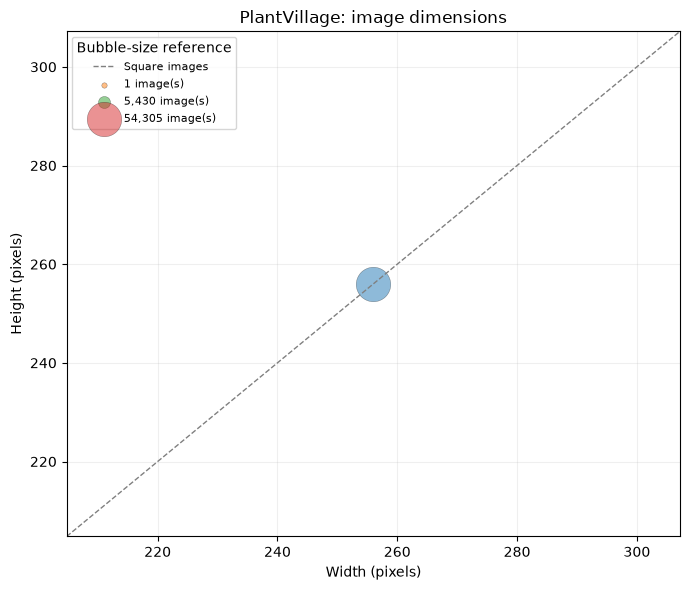

PlantDoc: 2,578 readable images; 1,506 unique resolutions (top 20 shown)


,resolution,images,percentage
0,1600 × 1200,64,2.48
1,800 × 600,58,2.25
2,1024 × 768,56,2.17
3,640 × 480,30,1.16
4,1200 × 1600,25,0.97
5,3264 × 2448,25,0.97
6,900 × 675,22,0.85
7,400 × 300,19,0.74
8,500 × 375,19,0.74
9,1200 × 900,19,0.74


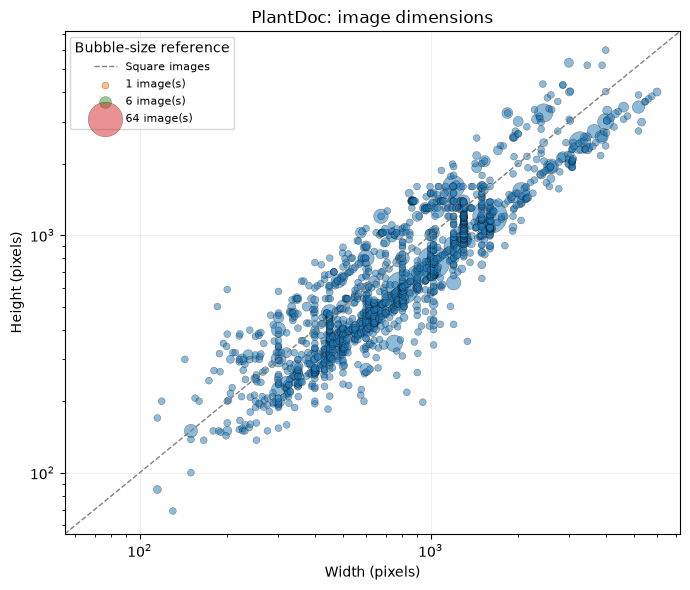

In [122]:
dimensions = inventory[inventory["readable"].astype(str).str.lower().eq("true")].copy()
dimensions[["width", "height"]] = dimensions[["width", "height"]].apply(pd.to_numeric)
dimension_frequencies = {}
for dataset, display_name in DATASET_LABELS.items():
    subset = dimensions[dimensions["dataset"] == dataset]
    if subset.empty:
        print(f"{display_name}: no readable images")
        continue

    frequency = (subset.groupby(["width", "height"]).size().rename("images")
                 .reset_index().sort_values(["images", "width", "height"],
                                            ascending=[False, True, True]).reset_index(drop=True))
    frequency["resolution"] = frequency["width"].astype(str) + " × " + frequency["height"].astype(str)
    frequency["percentage"] = (100 * frequency["images"] / len(subset)).round(2)
    dimension_frequencies[dataset] = frequency
    print(f"{display_name}: {len(subset):,} readable images; {len(frequency):,} unique resolutions (top 20 shown)")
    display(frequency[["resolution", "images", "percentage"]].head(20))

    max_count = frequency["images"].max()
    bubble_area = lambda count: 15 + 600 * count / max_count
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(frequency["width"], frequency["height"], s=bubble_area(frequency["images"]),
               alpha=.5, edgecolors="black", linewidths=.3)
    axis_min = min(frequency["width"].min(), frequency["height"].min()) * .8
    axis_max = max(frequency["width"].max(), frequency["height"].max()) * 1.2
    ax.plot([axis_min, axis_max], [axis_min, axis_max], linestyle="--", color="gray",
            linewidth=1, label="Square images")
    if axis_max / axis_min > 10:
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set(xlim=(axis_min, axis_max), ylim=(axis_min, axis_max),
           title=f"{display_name}: image dimensions", xlabel="Width (pixels)", ylabel="Height (pixels)")
    for count in sorted({1, max(1, max_count // 10), max_count}):
        ax.scatter([], [], s=bubble_area(count), alpha=.5, edgecolors="black", linewidths=.3,
                   label=f"{count:,} image(s)")
    ax.legend(title="Bubble-size reference", fontsize=8)
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{dataset}_dimension_bubbles.png", dpi=160)
    plt.show()


## 4. Image quality, duplicates, and leaf groups

Automated quality flags and counts are reported separately from the dimension analysis. The complete measurements, including minimum/maximum category sizes, remain available in `image_statistics.json`.

The issue table counts flagged entries across both datasets, including zero-count issue types. An image can have multiple flags, so these are not counts of unique images or groups; a missing split-list entry is a path without a corresponding file.

Exact SHA-256 duplicates are confirmed **byte-identical**; separate versions of the same leaf need not have identical hashes. PlantVillage leaf IDs are taken from the author's metadata where resolvable. Any possible leakage needs review before splitting data.


In [123]:
issue_descriptions = {
    "unreadable": "Image cannot be fully decoded.",
    "unassigned_split": "PlantVillage image is absent from both source split lists.",
    "missing_split_file": "PlantVillage source split lists a file that is not present.",
    "exact_duplicate": "Image shares its SHA-256 hash with another file; each copy is counted.",
    "same_leaf_across_splits": "Images with the same known leaf ID occur in different source splits.",
    "case_insensitive_filename_collision": "Relative file paths differ only by letter case and may conflict on some filesystems.",
}
flag_counts = flags["flag"].value_counts()
issue_types = list(issue_descriptions) + sorted(set(flag_counts.index) - set(issue_descriptions))
issue_rows = [
    {"issue_type": issue, "count": int(flag_counts.get(issue, 0)),
     "description": issue_descriptions.get(issue, "Unrecognized flag; inspect the entries below.")}
    for issue in issue_types
]
print("Automated issue counts (flagged entries):")
display(pd.DataFrame(issue_rows, columns=["issue_type", "count", "description"]))
if flags.empty:
    print("No automated flags in this run.")
else:
    display(flags.groupby(["dataset", "flag"]).size().rename("flagged_entries").reset_index())
    display(flags)
print("Confirmed byte-identical hash groups:", summary["exact_duplicate_hash_groups"])
print("Cross-partition hash groups:", summary["exact_duplicate_cross_partition_groups"])
print("PlantVillage leaf groups spanning splits:", summary["same_leaf_cross_split_groups"])


Automated issue counts (flagged entries):


,issue_type,count,description
0,unreadable,0,Image cannot be fully decoded.
1,unassigned_split,0,PlantVillage image is absent from both source ...
2,missing_split_file,0,PlantVillage source split lists a file that is...
3,exact_duplicate,66,Image shares its SHA-256 hash with another fil...
4,same_leaf_across_splits,0,Images with the same known leaf ID occur in di...
5,case_insensitive_filename_collision,12,Relative file paths differ only by letter case...


,dataset,flag,flagged_entries
0,plantdoc,case_insensitive_filename_collision,12
1,plantdoc,exact_duplicate,24
2,plantvillage,exact_duplicate,42


,flag,dataset,category,split,relative_path,details
0,exact_duplicate,plantvillage,Apple___healthy,train,plantvillage/raw/color/Apple___healthy/11beda6...,SHA-256 ec2fe5801c82d7ffff332b9429480c6a432830...
1,exact_duplicate,plantvillage,Apple___healthy,train,plantvillage/raw/color/Apple___healthy/13298d3...,SHA-256 ec2fe5801c82d7ffff332b9429480c6a432830...
2,exact_duplicate,plantvillage,Apple___healthy,test,plantvillage/raw/color/Apple___healthy/14896dc...,SHA-256 5d486b62abe59b8dea5aef6b63f887bacd12bb...
3,exact_duplicate,plantvillage,Apple___healthy,test,plantvillage/raw/color/Apple___healthy/c21cf42...,SHA-256 5d486b62abe59b8dea5aef6b63f887bacd12bb...
4,exact_duplicate,plantvillage,Apple___healthy,test,plantvillage/raw/color/Apple___healthy/1ab5e01...,SHA-256 372bc4a6e18895011eaa18638acf8cdd83db9c...
...,...,...,...,...,...,...
73,case_insensitive_filename_collision,plantdoc,Corn leaf blight,train,plantdoc/train/Corn leaf blight/northern-corn-...,Collides with: plantdoc/train/Corn leaf blight...
74,case_insensitive_filename_collision,plantdoc,Peach leaf,train,plantdoc/train/Peach leaf/Peach-Leaf.jpg,Collides with: plantdoc/train/Peach leaf/peach...
75,case_insensitive_filename_collision,plantdoc,Peach leaf,train,plantdoc/train/Peach leaf/peach-leaf.jpg,Collides with: plantdoc/train/Peach leaf/Peach...
76,case_insensitive_filename_collision,plantdoc,Potato leaf early blight,train,plantdoc/train/Potato leaf early blight/potato...,Collides with: plantdoc/train/Potato leaf earl...


Confirmed byte-identical hash groups: 33
Cross-partition hash groups: 16
PlantVillage leaf groups spanning splits: 0


### 4a. Exact duplicate groups: impact and supporting flags

Each SHA-256 group with at least two files gets **exactly one** `experiment_impact` value:

| Experiment impact | Meaning | Recommended next step |
| --- | --- | --- |
| `training_test_overlap` | Copies appear in PlantVillage train and at least one planned test set. | Exclude image from training; include image in testing. |
| `duplicate_test` | More than one copy is in the planned test images, without training overlap. | Deduplicate test images. |
| `duplicate_training` | More than one copy is in PlantVillage train, without test overlap. | Deduplicate training images. |
| `no_direct_impact` | The copies do not create duplicate training/test observations under the current plan. | No duplicate-related change needed; any conflicting labels still require review. |

These classifications take precedence **in the order shown**. PlantVillage train is the planned training set; PlantVillage test and PlantDoc test are test sets; PlantDoc train is unused. The final PlantVillage train/validation subdivision does not yet exist.

Three separate Boolean flags describe group properties without changing its primary classification: `label_conflict` (different original categories within a dataset), `cross_dataset` (PlantVillage and PlantDoc both contain the bytes), and `cross_source_split` (train/test overlap within one original dataset). Different names across datasets are **not automatically label conflicts**.

`duplicate_groups.csv` provides a group-level audit and one `recommended_action` per group. Conflicting labels always require review before using an affected image, including test images, even when the other copy is unused and the group is classified as `no_direct_impact`. `duplicate_group_members.csv` lists all original image paths and whether each is used for `training`, `evaluation`, or is `unused`. These are findings about **exact copies only**; neither source images nor partitions are changed. Rerun the inventory and the cell below to refresh recommendations after this correction.


In [ ]:
duplicate_groups = pd.read_csv(OUTPUT_DIR / "duplicate_groups.csv", keep_default_na=False)
duplicate_members = pd.read_csv(OUTPUT_DIR / "duplicate_group_members.csv", keep_default_na=False)
impact_order = ["training_test_overlap", "duplicate_test", "duplicate_training", "no_direct_impact"]
print("Exact duplicate groups:", summary["exact_duplicate_hash_groups"])
print("Additional properties:")
print("  Label conflicts:", summary["exact_duplicate_label_conflict_groups"])
print("  Cross-dataset groups:", summary["exact_duplicate_cross_dataset_groups"])
print("  Cross-source-split groups:", summary["exact_duplicate_cross_source_split_groups"])
if duplicate_groups.empty:
    print("No exact duplicate groups found.")
else:
    impact_counts = (duplicate_groups["experiment_impact"].value_counts()
                     .reindex(impact_order, fill_value=0).rename_axis("experiment_impact")
                     .reset_index(name="groups"))
    display(impact_counts)
    overview = duplicate_groups.assign(hash_id=duplicate_groups["sha256"].str[:12])
    display(overview[["hash_id", "copy_count", "source_partitions", "experiment_impact",
                      "training_copies", "evaluation_copies", "unused_copies",
                      "label_conflict", "cross_dataset", "cross_source_split", "recommended_action"]])
    urgent = duplicate_groups[
        duplicate_groups["experiment_impact"].eq("training_test_overlap")
        | duplicate_groups["label_conflict"].astype(str).str.lower().eq("true")
    ]
    if not urgent.empty:
        print("Member paths for training/test overlap or label-conflict groups:")
        display(duplicate_members[duplicate_members["sha256"].isin(urgent["sha256"])]
                .sort_values(["sha256", "dataset", "split", "category", "relative_path"]))


### 4b. Case-insensitive filename collision detection

`analyze_data.py` identifies groups of relative paths that become identical after `casefold()` but differ in capitalization. It writes the affected paths to `case_insensitive_filename_collisions.csv` and flags each member in `quality_flags.csv`. These are filename conflicts on case-insensitive filesystems, **not evidence that image content matches**. Images are not displayed or compared here.


In [125]:
collision_groups = pd.read_csv(OUTPUT_DIR / "case_insensitive_filename_collisions.csv", keep_default_na=False)
print(f"Case-insensitive filename collision groups: {len(collision_groups):,}")
display(collision_groups)


Case-insensitive filename collision groups: 6


,casefolded_path,relative_paths
0,plantdoc/train/apple rust leaf/car1.jpg,"[""plantdoc/train/Apple rust leaf/CAR1.jpg"", ""p..."
1,plantdoc/train/blueberry leaf/blueberry-leaf.jpg,"[""plantdoc/train/Blueberry leaf/Blueberry-Leaf..."
2,plantdoc/train/blueberry leaf/blueberry-leaves...,"[""plantdoc/train/Blueberry leaf/Blueberry-leav..."
3,plantdoc/train/corn leaf blight/northern-corn-...,"[""plantdoc/train/Corn leaf blight/Northern-Cor..."
4,plantdoc/train/peach leaf/peach-leaf.jpg,"[""plantdoc/train/Peach leaf/Peach-Leaf.jpg"", ""..."
5,plantdoc/train/potato leaf early blight/potato...,"[""plantdoc/train/Potato leaf early blight/pota..."
